In [ ]:
from probad.schema import TestItem, validate_items
from probad.utils import load_bengali_stopwords
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor, as_completed
from openai import OpenAI
from tqdm import tqdm

import json


DATA_PATH = Path("../data")
OUTPUT_PATH = Path("../results/validation")

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

train_data = list(TestItem.load_items(DATA_PATH / "train.jsonl"))
test_data = list(TestItem.load_items(DATA_PATH / "test.jsonl"))
val_data = list(TestItem.load_items(DATA_PATH / "val.jsonl"))

client = OpenAI(api_key = OPENAI_KEY)

MODEL = "gpt-6.2-sol"

VALIDATION_PROMPT = """
You are an independent validator for a Bengali proverb dataset. Another LLM generated each item.
Your job is to find real errors, not to rewrite or improve the item.

Each item contains: a Bengali proverb, its romanisation, its meaning, cultural notes, memorisation
prefix/target, and conversations in Bengali and English with three answer options
(correct = figurative meaning, literal = literal reading, plausible = believable distractor).

Check:
1. Proverb: Do you recognise it as an existing Bengali proverb (state your confidence)? Is the meaning right?
   Is it used figuratively in the conversations? If you do not recognise it, do NOT call it fake;
   set human_review_required = true.
2. Conversation: Natural, coherent, and does the situation actually call for this proverb?
   The proverb (or a close variant) must appear in it. The conversation must NOT state or paraphrase
   the proverb's meaning (that would give away the answer).
3. Bengali: Natural, grammatical, idiomatic? Flag machine-translated or wrong expressions.
   Regional and colloquial forms are acceptable.
4. Options: Exactly one option must be correct. The literal option must be a faithful literal reading.
   The plausible option must be wrong but believable; flag it if it could also be defended as correct.
   Flag surface cues: the correct option reusing distinctive words from the conversation, or being
   clearly longer or more specific than the others.
5. Cross-language: Bengali and English conversations describe the same situation; options match in meaning.
6. Culture: Cultural notes and references are correct. Put uncertain claims down as "observation"
   and send them to human review.
7. Romanisation: Matches the Bengali proverb.
8. Memorisation: prefix + target together reconstruct the proverb, in both Bengali and romanised form.
9. Structure: Contradictions, missing fields, or suspicious metadata.

Rules:
- Report only issues you can point to. Quote the exact text span as evidence.
- Use the exact JSON path for "field" (e.g. "conversations[1].bn", "options.plausible").
- Severity:
  critical = the gold answer is wrong, the question is ambiguous, or the proverb/meaning is wrong
  major    = a real error that hurts the item but can be fixed
  minor    = small language or style problem
  observation = uncertain claim or comment, not an error
- Status must follow severity:
  any critical -> REJECT (unfixable) or NEEDS_REVISION (fixable)
  any major    -> NEEDS_REVISION
  only minor or observation -> PASS_WITH_MINOR_ISSUES
  none         -> PASS
- Scores 1-5 (5 excellent, 4 minor flaws, 3 acceptable, 2 significant problems, 1 wrong or unusable).
  Use null if the field is missing or not applicable.
- Write issues in English and quote Bengali as it appears.

Return JSON only, with the keys in this order: issues, scores, status, human_review_required,
human_review_reason, proverb_recognised.
"""


SCORE = {"type": ["integer", "null"], "minimum": 1, "maximum": 5}
DIMS = ["proverb_semantics", "context_quality", "bengali_naturalness", "cultural_accuracy",
        "translation_alignment", "answer_option_quality", "romanisation",
        "memorisation_consistency", "structural_consistency"]

VALIDATION_SCHEMA = {
    "type": "object", "additionalProperties": False,
    "required": ["issues", "scores", "status", "human_review_required", "human_review_reason", "proverb_recognised"],
    "properties": {
        "issues": {"type": "array", "items": {
            "type": "object", "additionalProperties": False,
            "required": ["field", "severity", "evidence", "issue", "suggestion"],
            "properties": {
                "field": {"type": "string"},
                "severity": {"enum": ["critical", "major", "minor", "observation"]},
                "evidence": {"type": "string"},
                "issue": {"type": "string"},
                "suggestion": {"type": "string"}}}},
        "scores": {"type": "object", "additionalProperties": False, "required": DIMS,
                   "properties": {d: SCORE for d in DIMS}},
        "status": {"enum": ["PASS", "PASS_WITH_MINOR_ISSUES", "NEEDS_REVISION", "REJECT"]},
        "human_review_required": {"type": "boolean"},
        "human_review_reason": {"type": ["string", "null"]},
        "proverb_recognised": {"enum": ["yes_confident", "yes_unsure", "no"]}}}


def validate_item(item):

    item_data = item.model_dump()

    response = client.responses.create(
        model=MODEL,
        reasoning={"effort": "medium"},
        input=[
            {"role": "system", "content": VALIDATION_PROMPT},
            {
                "role": "user",
                "content": json.dumps(item_data, ensure_ascii=False)
            }
        ],
        text={
            "format": {
                "type": "json_schema",
                "name": "validation",
                "schema": VALIDATION_SCHEMA,
                "strict": True
            }
        }
    )

    # Extract validation result
    result = json.loads(response.output_text)

    # Extract API usage
    usage = response.usage

    return {
        "item_id": getattr(item, "item_id", None),
        "original_data": item_data,
        "validation": result,

        "api_metadata": {
            "response_id": response.id,
            "model": response.model,
            "status": response.status,
            "created_at": datetime.fromtimestamp(
                response.created_at, tz=timezone.utc
            ).isoformat(),
            "completed_at": (
                datetime.fromtimestamp(
                    response.completed_at, tz=timezone.utc
                ).isoformat()
                if response.completed_at else None
            ),
            "reasoning_effort": (
                response.reasoning.effort if response.reasoning else None
            ),
            "service_tier": response.service_tier,
        },

        "payload_metadata": {
            "input_tokens": usage.input_tokens if usage else None,
            "output_tokens": usage.output_tokens if usage else None,
            "total_tokens": usage.total_tokens if usage else None,
            "reasoning_tokens": (
                usage.output_tokens_details.reasoning_tokens
                if usage and usage.output_tokens_details else None
            ),
            "cached_tokens": (
                usage.input_tokens_details.cached_tokens
                if usage and usage.input_tokens_details else None
            ),
        }
    }


def validate_dataset(dataset, name, max_workers=5):

    output_file = OUTPUT_PATH / f"{name}_validation.jsonl"

    results = []

    with open(output_file, "w", encoding="utf-8") as f:

        with ThreadPoolExecutor(max_workers=max_workers) as executor:

            futures = {
                executor.submit(validate_item, item): item
                for item in dataset
            }

            for future in tqdm(
                as_completed(futures),
                total=len(futures),
                desc=f"Validating {name}"
            ):

                item = futures[future]

                try:
                    result = future.result()

                    f.write(json.dumps(result, ensure_ascii=False) + "\n")
                    f.flush()

                    results.append(result)

                except Exception as e:

                    error = {
                        "item_id": getattr(item, "item_id", None),
                        "error": str(e)
                    }

                    f.write(json.dumps(error, ensure_ascii=False) + "\n")
                    f.flush()

                    print(f"Error: {error['item_id']} -> {e}")

    print(f"\n{name}: validated {len(results)}/{len(dataset)} items")
    print(f"Saved to: {output_file}")

    return results

In [31]:
validate_item(train_data[0])

{'item_id': 'prv_008_1',
 'original_data': {'item_id': 'prv_008_1',
  'proverb': {'proverb_id': 'prv_008',
   'bengali': 'ইটটি মারলে পাটকেলটি খেতে হয়',
   'romanised': 'Itti marle patkelti khete hoy.',
   'literal_gloss': 'Throw a brick and you get a stone back.',
   'meaning': {'en': 'If you hurt someone, expect to be hurt back.',
    'bn': 'কারও ক্ষতি করলে তার ফল নিজেকেও ভোগ করতে হয়।'},
   'figurative': True,
   'region': 'both',
   'cultural_note': '',
   'false_friends': [],
   'respelled': None},
  'en': {'turns': [{'speaker': 'Rajesh',
     'text': 'Sumon trolled his ex-colleague online for weeks, and now she has posted all his old embarrassing messages.'},
    {'speaker': 'Ipsita', 'text': 'Itti marle patkelti khete hoy.'}],
   'proverb_speaker': 'Ipsita',
   'options': {'correct': 'Sumon hurt her first, so he should have expected to be hurt back.',
    'literal': 'Throw a brick at someone and a stone comes back at you.',
    'plausible': 'Ipsita thinks the ex-colleague starte

In [34]:
val_results = validate_dataset(val_data[:6], "val_process_test")

Validating val_process_test: 100%|██████████| 6/6 [00:33<00:00,  5.52s/it]


val_process_test: validated 6/6 items
Saved to: ../results/validation/val_process_test_validation.jsonl


In [35]:
val_results = validate_dataset(val_data, f"val-{MODEL}")

Validating val-gpt-6.2-sol: 100%|██████████| 75/75 [04:21<00:00,  3.48s/it]


val-gpt-6.2-sol: validated 75/75 items
Saved to: ../results/validation/val-gpt-6.2-sol_validation.jsonl


In [36]:
train_results = validate_dataset(train_data, f"train-{MODEL}")

Validating train-gpt-6.2-sol: 100%|██████████| 300/300 [14:46<00:00,  2.96s/it]


train-gpt-6.2-sol: validated 300/300 items
Saved to: ../results/validation/train-gpt-6.2-sol_validation.jsonl


In [37]:
test_results = validate_dataset(test_data, f"test-{MODEL}")

Validating test-gpt-6.2-sol: 100%|██████████| 600/600 [29:59<00:00,  3.00s/it]


test-gpt-6.2-sol: validated 600/600 items
Saved to: ../results/validation/test-gpt-6.2-sol_validation.jsonl


In [38]:
test_results[0]

{'item_id': 'prv_002_1',
 'original_data': {'item_id': 'prv_002_1',
  'proverb': {'proverb_id': 'prv_002',
   'bengali': 'অল্প বিদ্যা ভয়ংকরী',
   'romanised': 'Olpo bidya bhoyonkori.',
   'literal_gloss': 'Little learning is dangerous.',
   'meaning': {'en': 'A little knowledge is a dangerous thing: half-knowledge makes people overconfident.',
    'bn': 'অল্প জ্ঞান নিয়ে বেশি জাহির করা বিপজ্জনক।'},
   'figurative': False,
   'region': 'both',
   'cultural_note': '',
   'false_friends': [],
   'respelled': None},
  'en': {'turns': [{'speaker': 'Ma',
     'text': 'Tublu watched two videos online and now he wants to fix the main switchboard himself.'},
    {'speaker': 'Baba',
     'text': "Don't let him touch it. Olpo bidya bhoyonkori."}],
   'proverb_speaker': 'Baba',
   'options': {'correct': 'Tublu knows just enough to feel confident, which makes him likely to cause an accident.',
    'literal': 'Having studied only a little in school is a truly frightening thing.',
    'plausible': '

{'test': 600, 'train': 300, 'val': 75} items | 4874 issues
status matches the severity rule for 100.0% of items


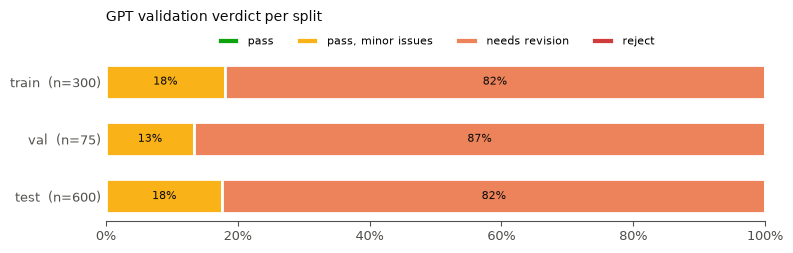

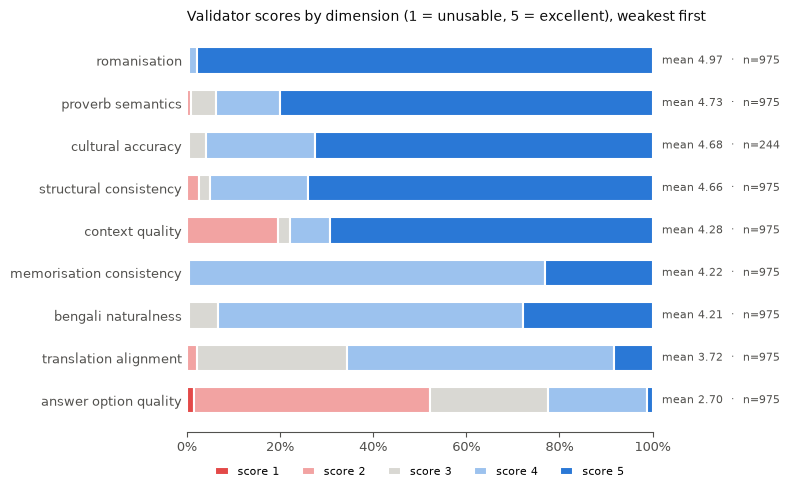

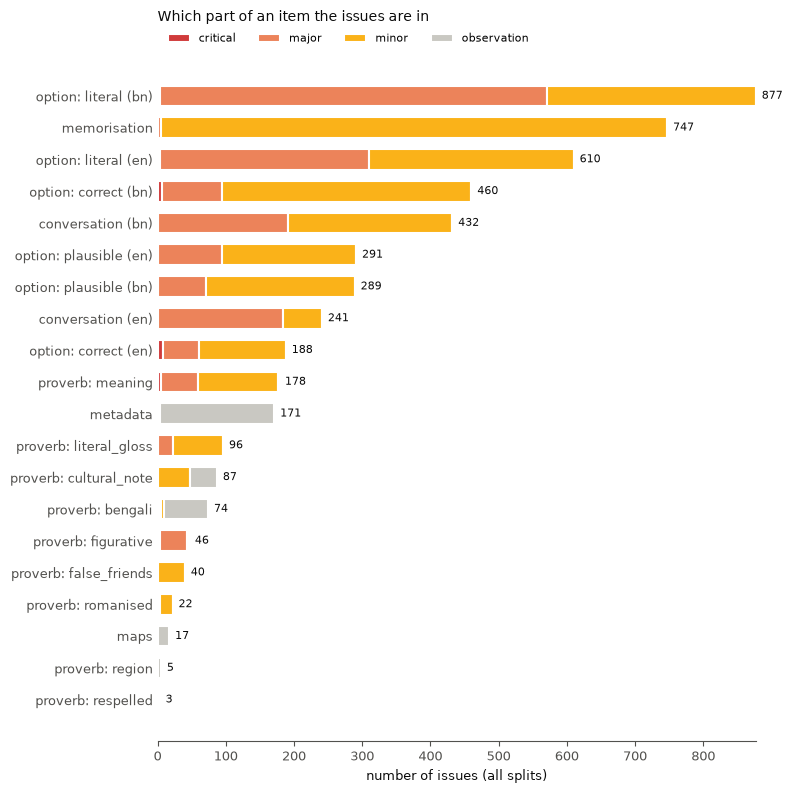

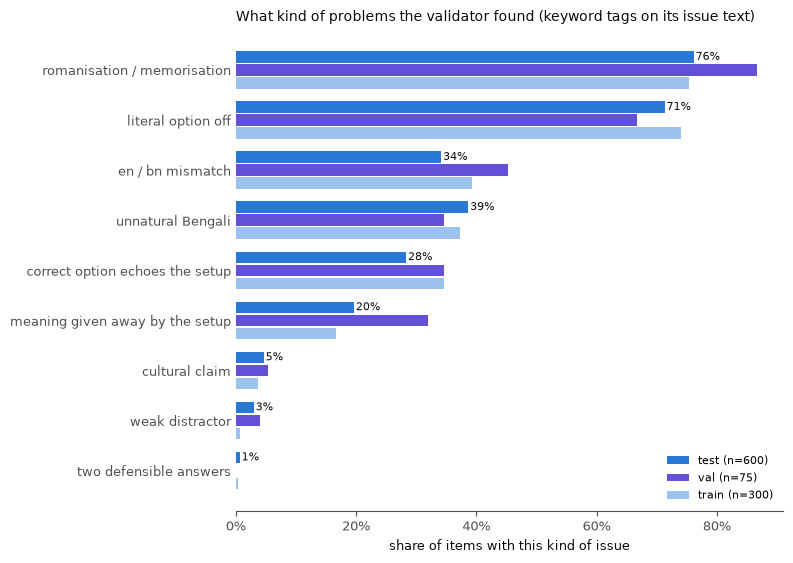

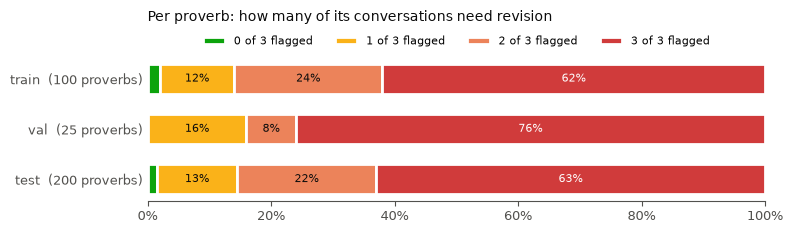

,items,pass_,minor,revise,reject,issues_per_item,human_review,recognised,in_tok,out_tok,cached_tok,cost_$
split,,,,,,,,,,,,
train,300,0.0,0.180,0.820,0.0,4.933,0.323,0.863,510269,263341,317100,3.051
val,75,0.0,0.133,0.867,0.0,5.947,0.480,0.987,128373,75764,75047,0.872
test,600,0.0,0.177,0.823,0.0,4.913,0.207,0.957,1027078,532504,634200,6.174


total cost ≈ $10.10


In [40]:
import re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

VFIG = Path("figs_validation"); VFIG.mkdir(exist_ok=True)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
STATUS = {"PASS": "#0ca30c", "PASS_WITH_MINOR_ISSUES": "#fab219", "NEEDS_REVISION": "#ec835a", "REJECT": "#d03b3b"}
STATUS_NAME = {"PASS": "pass", "PASS_WITH_MINOR_ISSUES": "pass, minor issues", "NEEDS_REVISION": "needs revision", "REJECT": "reject"}
SEV = {"critical": "#d03b3b", "major": "#ec835a", "minor": "#fab219", "observation": "#c9c8c2"}
SCORE_COL = {1: "#e34948", 2: "#f2a3a2", 3: "#d9d8d3", 4: "#9cc2ee", 5: "#2a78d6"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9})

SPLITS = {"train": train_results, "val": val_results, "test": test_results}

# ---- tidy tables: one row per item, one row per issue
def field_group(f):
    """'en.turns[0].text' -> ('conversation', 'en'); 'bn.options.correct' -> ('option: correct', 'bn')."""
    parts = re.sub(r"\[\d+\]", "", f).split(".")
    if parts[0] in ("en", "bn"):
        lang, rest = parts[0], parts[1:]
        if rest and rest[0] == "options":
            return (f"option: {rest[1]}" if len(rest) > 1 else "options"), lang
        return "conversation", lang
    if parts[0] == "proverb":
        return (f"proverb: {parts[1]}" if len(parts) > 1 else "proverb"), "-"
    return {"memorisation": "memorisation", "meta": "metadata"}.get(parts[0], parts[0]), "-"

THEMES = {
    "meaning given away by the setup": r"give[sn]? away|paraphras|explicitly (stat|identif)|spells? out|reveal|leak",
    "correct option echoes the setup": r"echo|repeat|mirror|overlap|by matching|copies|reuses|verbatim",
    "two defensible answers": r"ambigu|also (be )?(correct|defensible|valid)|more than one",
    "weak distractor": r"too obvious|implausible|easily (ruled|dismissed)|not believable",
    "literal option off": r"literal",
    "unnatural Bengali": r"unnatural|awkward|machine|grammat|idiomatic",
    "en / bn mismatch": r"whereas|mismatch|inconsisten|does not match|differ",
    "cultural claim": r"cultur",
    "romanisation / memorisation": r"romanis|prefix|target",
}

items, issues = [], []
for split, res in SPLITS.items():
    for r in res:
        v, o = r["validation"], r["original_data"]
        text = " ".join(i["issue"] for i in v["issues"]).lower()
        sev = [i["severity"] for i in v["issues"]]
        rule = ("NEEDS_REVISION" if "critical" in sev or "major" in sev else
                "PASS_WITH_MINOR_ISSUES" if sev else "PASS")
        items.append({"split": split, "item_id": r["item_id"], "proverb_id": o["proverb"]["proverb_id"],
                      "status": v["status"], "rule_status": rule, "n_issues": len(sev),
                      "human_review": v["human_review_required"], "recognised": v.get("proverb_recognised"),
                      **{f"s_{k}": s for k, s in v["scores"].items()},
                      **{f"t_{t}": bool(re.search(p, text)) for t, p in THEMES.items()},
                      **{f"tok_{k}": r.get("payload_metadata", {}).get(f"{k}_tokens", 0)
                         for k in ("input", "output", "reasoning", "cached")}})
        for i in v["issues"]:
            g, lang = field_group(i["field"])
            issues.append({"split": split, "item_id": r["item_id"], "group": g, "lang": lang, **i})
IT, ISS = pd.DataFrame(items), pd.DataFrame(issues)
DIMS = [c[2:] for c in IT if c.startswith("s_")]
print(IT.groupby("split").size().to_dict(), "items |", len(ISS), "issues")

# status the model gave vs the severity rule (REJECT counts as agreeing with NEEDS_REVISION)
agree = (IT["status"].replace("REJECT", "NEEDS_REVISION") == IT["rule_status"]).mean()
print(f"status matches the severity rule for {agree:.1%} of items")

# ---- V1. status per split
order = list(STATUS)
tab = pd.crosstab(IT["split"], IT["status"], normalize="index").reindex(index=list(SPLITS), columns=order).fillna(0)
n = IT.groupby("split").size()
fig, ax = plt.subplots(figsize=(8, 2.6))
left = np.zeros(len(tab))
for s in order:
    w = tab[s].to_numpy()
    ax.barh(range(len(tab)), w, left=left, height=0.6, color=STATUS[s], edgecolor="white", lw=2, label=STATUS_NAME[s])
    for y, (l, wi) in enumerate(zip(left, w)):
        if wi >= 0.06:
            ax.text(l + wi / 2, y, f"{wi:.0%}", ha="center", va="center", fontsize=8,
                    color=INK if s in ("PASS_WITH_MINOR_ISSUES", "NEEDS_REVISION") else "white")
    left += w
ax.set_yticks(range(len(tab)), [f"{s}  (n={n[s]})" for s in tab.index]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=8)
ax.set_title("GPT validation verdict per split", color=INK, fontsize=10, loc="left", pad=26)
plt.tight_layout(); fig.savefig(VFIG / "V1_status.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- V2. score distribution per quality dimension (all splits)
dim_order = sorted(DIMS, key=lambda d: IT[f"s_{d}"].mean())
fig, ax = plt.subplots(figsize=(8, 0.42 * len(DIMS) + 1.2))
for y, d in enumerate(dim_order):
    col = IT[f"s_{d}"].dropna().astype(int)
    share = col.value_counts(normalize=True).reindex(range(1, 6)).fillna(0)
    left = 0
    for sc in range(1, 6):
        ax.barh(y, share[sc], left=left, height=0.62, color=SCORE_COL[sc], edgecolor="white", lw=1.5,
                label=str(sc) if y == 0 else None)
        left += share[sc]
    ax.text(1.02, y, f"mean {col.mean():.2f}  ·  n={len(col)}", va="center", fontsize=8, color=MUTED,
            transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(dim_order)), [d.replace("_", " ") for d in dim_order]); ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.spines["left"].set_visible(False)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.06), fontsize=8, handlelength=1.2,
          labels=[f"score {i}" for i in range(1, 6)])
ax.set_title("Validator scores by dimension (1 = unusable, 5 = excellent), weakest first",
             color=INK, fontsize=10, loc="left")
plt.tight_layout(); fig.savefig(VFIG / "V2_scores.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- V3. where the issues are: field x severity
ISS["where"] = ISS["group"] + np.where(ISS["lang"] != "-", " (" + ISS["lang"] + ")", "")
cnt = pd.crosstab(ISS["where"], ISS["severity"]).reindex(columns=list(SEV)).fillna(0)
cnt = cnt.loc[cnt.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 0.34 * len(cnt) + 1.2))
left = np.zeros(len(cnt))
for s in SEV:
    ax.barh(range(len(cnt)), cnt[s], left=left, height=0.65, color=SEV[s], edgecolor="white", lw=1.5, label=s)
    left += cnt[s].to_numpy()
for y, tot in enumerate(left):
    ax.text(tot + left.max() * 0.01, y, f"{int(tot)}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(cnt)), cnt.index); ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.set_xlabel("number of issues (all splits)")
ax.legend(frameon=False, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
ax.set_title("Which part of an item the issues are in", color=INK, fontsize=10, loc="left", pad=24)
plt.tight_layout(); fig.savefig(VFIG / "V3_issue_fields.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- V4. issue themes: share of items with at least one issue of that kind
th = pd.DataFrame({t: IT.groupby("split")[f"t_{t}"].mean() for t in THEMES}).T.reindex(columns=list(SPLITS))
th = th.loc[th.mean(axis=1).sort_values().index]
SPLIT_COL = {"train": "#9cc2ee", "val": "#6250d6", "test": "#2a78d6"}
fig, ax = plt.subplots(figsize=(8, 0.5 * len(th) + 1.2))
h = 0.26
for j, s in enumerate(SPLITS):
    ax.barh(np.arange(len(th)) + (j - 1) * h, th[s], height=h - 0.03, color=SPLIT_COL[s], label=f"{s} (n={n[s]})")
for y, t in enumerate(th.index):                       # label the test bar
    ax.text(th.loc[t, "test"] + 0.003, y + h, f"{th.loc[t, 'test']:.0%}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(th)), th.index); ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_xlabel("share of items with this kind of issue")
ax.legend(frameon=False, fontsize=8, loc="lower right", reverse=True)
ax.set_title("What kind of problems the validator found (keyword tags on its issue text)",
             color=INK, fontsize=10, loc="left")
plt.tight_layout(); fig.savefig(VFIG / "V4_issue_themes.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- V5. proverb level: how many of a proverb's 3 conversations were flagged
IT["flagged"] = IT["status"].isin(["NEEDS_REVISION", "REJECT"])
pv = IT.groupby(["split", "proverb_id"])["flagged"].sum().reset_index()
share = pd.crosstab(pv["split"], pv["flagged"], normalize="index").reindex(index=list(SPLITS)).fillna(0)
cols = {0: "#0ca30c", 1: "#fab219", 2: "#ec835a", 3: "#d03b3b"}
fig, ax = plt.subplots(figsize=(8, 2.4))
left = np.zeros(len(share))
for k in sorted(share.columns):
    w = share[k].to_numpy()
    ax.barh(range(len(share)), w, left=left, height=0.6, color=cols.get(k, "#d03b3b"), edgecolor="white", lw=2,
            label=f"{k} of 3 flagged")
    for y, (l, wi) in enumerate(zip(left, w)):
        if wi >= 0.06:
            ax.text(l + wi / 2, y, f"{wi:.0%}", ha="center", va="center", fontsize=8, color="white" if k in (0, 3) else INK)
    left += w
npv = pv.groupby("split").size()
ax.set_yticks(range(len(share)), [f"{s}  ({npv[s]} proverbs)" for s in share.index]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=8)
ax.set_title("Per proverb: how many of its conversations need revision", color=INK, fontsize=10, loc="left", pad=26)
plt.tight_layout(); fig.savefig(VFIG / "V5_per_proverb.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- summary table (paste into the paper)
summary = IT.groupby("split").agg(
    items=("item_id", "size"), pass_=("status", lambda s: (s == "PASS").mean()),
    minor=("status", lambda s: (s == "PASS_WITH_MINOR_ISSUES").mean()),
    revise=("status", lambda s: (s == "NEEDS_REVISION").mean()), reject=("status", lambda s: (s == "REJECT").mean()),
    issues_per_item=("n_issues", "mean"), human_review=("human_review", "mean"),
    recognised=("recognised", lambda s: (s == "yes_confident").mean()),
    in_tok=("tok_input", "sum"), out_tok=("tok_output", "sum"), cached_tok=("tok_cached", "sum")).reindex(list(SPLITS))
PRICE_IN, PRICE_CACHED, PRICE_OUT = 2.00, 0.10, 10.00       # gpt-6.2-sol standard $/1M
summary["cost_$"] = ((summary["in_tok"] - summary["cached_tok"]) * PRICE_IN + summary["cached_tok"] * PRICE_CACHED
                     + summary["out_tok"] * PRICE_OUT) / 1e6
display(summary.round(3))
print(f"total cost ≈ ${summary['cost_$'].sum():.2f}")


# ---- V6. do flagged items change model accuracy? (needs a results CSV from the run notebook)
def flagged_vs_accuracy(raw_csv, title=None, n_boot=2000, seed=0):
    """raw_csv: e.g. results/bloomz-7b1-mt/raw/x1_bn.csv. Item accuracy = mean over option orders."""
    r = pd.read_csv(raw_csv) if isinstance(raw_csv, (str, Path)) else raw_csv
    acc = r.groupby(["item_id", "proverb_id"])["correct"].mean().reset_index()
    it = IT[IT["split"].isin(r["split"].unique())] if "split" in r else IT
    m = acc.merge(it, on=["item_id", "proverb_id"], how="inner")
    print(f"{len(m)} of {len(acc)} scored items have a validation record")
    groups = {"all items": m.index == m.index, "passed (pass / minor)": ~m["flagged"],
              "needs revision / reject": m["flagged"].to_numpy(),
              "meaning given away": m["t_meaning given away by the setup"].to_numpy(),
              "correct option echoes setup": m["t_correct option echoes the setup"].to_numpy(),
              "two defensible answers": m["t_two defensible answers"].to_numpy()}
    rng = np.random.default_rng(seed)
    rows = []
    for g, mask in groups.items():
        d = m[mask]
        if len(d) < 5:
            continue
        pids = d["proverb_id"].unique()
        by = d.groupby("proverb_id")["correct"].agg(["sum", "count"]).loc[pids]
        pick = rng.integers(0, len(pids), (n_boot, len(pids)))
        boot = by["sum"].to_numpy()[pick].sum(1) / by["count"].to_numpy()[pick].sum(1)
        rows.append((g, d["correct"].mean(), *np.percentile(boot, [2.5, 97.5]), len(d)))
    res = pd.DataFrame(rows, columns=["group", "acc", "lo", "hi", "n"])
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(res) + 1.3))
    y = np.arange(len(res))
    base = res["acc"].iloc[0]
    ax.axvline(base, color=GRID, lw=6, zorder=0)
    ax.hlines(y, res["lo"], res["hi"], color=MUTED, lw=1.5, zorder=1)
    ax.scatter(res["acc"], y, s=60, zorder=2, edgecolors="white", linewidths=1,
               color=[INK, "#0ca30c", "#ec835a", "#2a78d6", "#2a78d6", "#2a78d6"][:len(res)])
    for yi, (a, hi, k) in enumerate(zip(res["acc"], res["hi"], res["n"])):
        ax.text(hi + 0.01, yi, f"{a:.1%}  (n={k})", va="center", fontsize=8, color=INK, clip_on=False)
    ax.set_yticks(y, res["group"]); ax.invert_yaxis(); ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.set_xlim(max(0, res["lo"].min() - 0.05), min(1.0, res["hi"].max() + 0.12))
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("model accuracy (mean over option orders, 95% CI by proverb)")
    ax.set_title(title or f"Model accuracy on items the validator flagged\n{Path(str(raw_csv)).name}",
                 color=INK, fontsize=10, loc="left")
    plt.tight_layout(); fig.savefig(VFIG / f"V6_flagged_vs_acc_{Path(str(raw_csv)).stem}.png", dpi=150,
                                    bbox_inches="tight"); plt.show()
    return res